In [1]:
import matplotlib.colors
import matplotlib.pyplot as plt
import numpy as np
import astropy.units as u
import astropy.visualization
import named_arrays as na
import esis

In [2]:
axis_x = "scene_x"
axis_y = "scene_y"

scene = esis.flights.f2.data.synth.scene_dem(
    axis_detector_x=axis_x,
    axis_detector_y=axis_y,
)
scene.outputs.shape

Files Downloaded:   0%|          | 0/1 [00:00<?, ?file/s]

aiapy.aia_pointing_table.csv:   0%|          | 0.00/4.92M [00:00<?, ?B/s]

2026-10-22 17:33:39 - fiasco - WARNING: VerifyWarning: Invalid 'BLANK' keyword in header.  The 'BLANK' keyword is only applicable to integer data, and will be ignored in this HDU.


2026-10-22 17:33:40 - fiasco - WARNING: VerifyWarning: Invalid 'BLANK' keyword in header.  The 'BLANK' keyword is only applicable to integer data, and will be ignored in this HDU.


2026-10-22 17:33:43 - fiasco - WARNING: VerifyWarning: Invalid 'BLANK' keyword in header.  The 'BLANK' keyword is only applicable to integer data, and will be ignored in this HDU.


...

Files Downloaded:   0%|          | 0/1 [00:00<?, ?file/s]

aiapy.aia_V10_20201119_190000_response_table.txt:   0%|          | 0.00/1.59k [00:00<?, ?B/s]

Files Downloaded:   0%|          | 0/1 [00:00<?, ?file/s]

aiapy.aia_V8_all_fullinst.genx:   0%|          | 0.00/5.43M [00:00<?, ?B/s]

{'line': 22, 'scene_y': 833, 'scene_x': 834, 'velocity': 20}

In [3]:
width = np.diff(scene.inputs.wavelength, axis="velocity")
radiance = (scene.outputs * width).sum("velocity")

rest = scene.inputs.wavelength_rest
mean = radiance.mean((axis_x, axis_y))
fraction = mean / mean.sum("line")

print(f"{'wavelength':>12}{'radiance':>12}{'fraction':>10}")
for i in np.argsort(-mean.ndarray.value):
    index = dict(line=i)
    print(
        f"{rest[index].ndarray.to_value(u.AA):12.3f}"
        f"{mean[index].ndarray.value:12.1f}"
        f"{fraction[index].ndarray.value:10.3f}"
    )

  wavelength    radiance  fraction
     499.406       291.5     0.271
     465.221       234.5     0.218
     520.665       141.1     0.131
     436.733        86.1     0.080
     434.927        52.7     0.049
     430.454        52.4     0.049
     431.323        30.9     0.029
     435.646        22.6     0.021
     447.357        20.7     0.019
     443.973        17.5     0.016
     467.427        15.6     0.014
     445.700        14.2     0.013
     433.179        14.2     0.013
     510.042        13.5     0.013
     482.994        11.5     0.011
     481.489         9.2     0.009
     431.198         8.7     0.008
     436.660         8.4     0.008
     487.042         8.3     0.008
     444.219         8.0     0.007
     434.730         7.8     0.007
     439.176         6.1     0.006


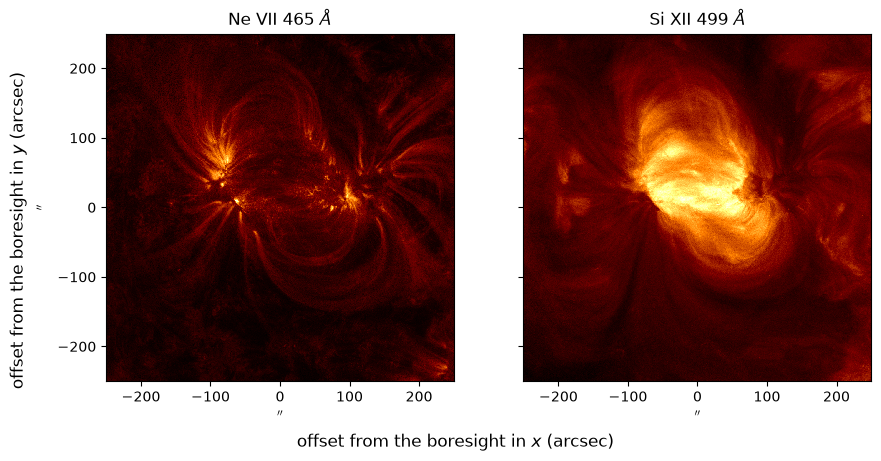

In [4]:
lines = {
    r"Ne VII 465 $\AA$": esis.flights.f2.wavelength_Ne_VII,
    r"Si XII 499 $\AA$": esis.flights.f2.wavelength_Si_XII,
}

with astropy.visualization.quantity_support():
    fig, axs = plt.subplots(
        ncols=2,
        figsize=(9, 4.5),
        sharey=True,
        constrained_layout=True,
    )
    for ax, (name, w) in zip(axs, lines.items()):
        index = np.argmin(np.abs(rest - w), axis="line")
        na.plt.pcolormesh(
            scene.inputs.position,
            C=np.sqrt(radiance[index].value),
            ax=ax,
            cmap="afmhot",
        )
        ax.set_title(name)
        ax.set_aspect("equal")
    fig.supxlabel("offset from the boresight in $x$ (arcsec)")
    fig.supylabel("offset from the boresight in $y$ (arcsec)")

In [5]:
instrument = esis.flights.f2.optics.design_single(num_distribution=0)
system = instrument.system
system.sensor.timedelta_exposure, system.sensor.read_noise

(<Quantity 1.2 s>, <Quantity 10.5 electron>)

In [6]:
linear = system.linearize(
    wavelength=na.linspace(
        start=instrument.wavelength_min,
        stop=instrument.wavelength_max,
        axis="_wavelength",
        num=105,
    ),
    degree=2,
    degree_distortion=3,
)

axis_field = (axis_x, axis_y)
electrons = 0
for i in range(rest.shape["line"]):
    line = scene[dict(line=i)].explicit
    weights = linear.weights(
        coordinates=line.inputs,
        axis_wavelength="velocity",
        axis_field=axis_field,
    )
    image = linear.image_from_weights(
        weights,
        line,
        axis_wavelength="velocity",
        axis_field=axis_field,
        integrate=False,
    )
    electrons = electrons + image.outputs.sum("velocity")

# the single readout of the sensor
electrons = na.random.normal(loc=electrons, scale=linear.sensor.read_noise)

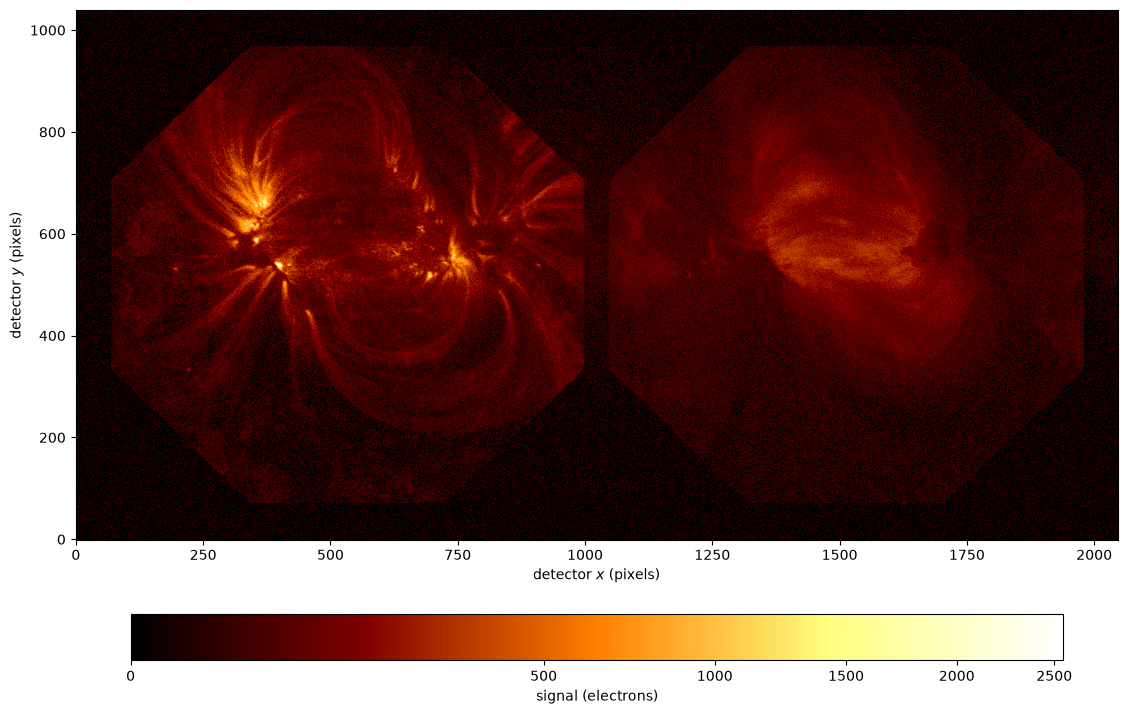

In [7]:
signal = electrons.to(u.electron).value.ndarray_aligned(("detector_y", "detector_x"))

fig, ax = plt.subplots(figsize=(12, 7), constrained_layout=True)
img = ax.imshow(
    signal,
    norm=matplotlib.colors.PowerNorm(gamma=1 / 2, vmin=0),
    origin="lower",
    cmap="afmhot",
    interpolation="none",
)
ax.set_xlabel("detector $x$ (pixels)")
ax.set_ylabel("detector $y$ (pixels)")
colorbar = fig.colorbar(img, ax=ax, orientation="horizontal", shrink=0.8)
colorbar.set_label("signal (electrons)")